# Коэффициент конкордации Кендалла — решение двух заданий

[Исходное задание](https://github.com/junaart/ForStudents/blob/main/Big_Data/Lesson_4/%D0%97%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BA%D0%BE%D0%BD%D0%ba%D0%BE%D1%80%D0%B4%D0%B0%D1%86%D0%B8%D1%8F.ipynb). Запускайте ячейки сверху вниз в Google Colab. Используются `pandas`, `scipy` и `matplotlib`, которые доступны в стандартной среде Colab.

Для $m$ экспертов и $n$ объектов: $S=\sum_j(R_j-m(n+1)/2)^2$, $W=12S/[m^2(n^3-n)-m\sum_i T_i]$, где $T_i=\sum_g(t_{ig}^3-t_{ig})$ для групп одинаковых оценок. При отсутствии совпадений $T_i=0$. Гипотезу $H_0$ об отсутствии согласованности проверяем при $\alpha=0{,}05$ по приближённой статистике $\chi^2=m(n-1)W$ с $n-1$ степенями свободы.


## Расчёт W и импорт библиотек


In [1]:
# Задание: коэффициент конкордации Кендалла (ЖКХ)
# Выполняйте ячейки по порядку в Google Colab.

from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.stats import chi2, rankdata


def concordance(matrix):
    """W Кендалла для строк-экспертов и столбцов-объектов, с поправкой на связи."""
    m = len(matrix)
    n = len(matrix[0])
    if m < 2 or n < 2 or any(len(row) != n for row in matrix):
        raise ValueError("Нужна прямоугольная матрица: минимум 2 эксперта и 2 объекта")

    # Средние ранги сохраняют порядок объектов и корректно учитывают равенства.
    ranks = [rankdata(row, method="average").tolist() for row in matrix]
    rank_sums = [sum(ranks[i][j] for i in range(m)) for j in range(n)]
    mean_rank_sum = m * (n + 1) / 2
    S = sum((total - mean_rank_sum) ** 2 for total in rank_sums)

    # Для каждой группы из t одинаковых оценок: T = t^3 - t.
    tie_correction = sum(
        count**3 - count
        for row in matrix
        for count in Counter(row).values()
        if count > 1
    )
    denominator = m**2 * (n**3 - n) - m * tie_correction
    W = 12 * S / denominator

    # При H0 (согласованности нет) статистика приближённо имеет распределение χ².
    chi_square = m * (n - 1) * W
    p_value = chi2.sf(chi_square, df=n - 1)
    return {
        "ranks": ranks,
        "sums": rank_sums,
        "S": S,
        "tie_correction": tie_correction,
        "W": W,
        "chi_square": chi_square,
        "df": n - 1,
        "p_value": p_value,
    }


alpha = 0.05



## Задание 1. Очередность капитального ремонта

Четыре ведомства ранжировали восемь домов. Ранг 1 означает наивысший приоритет. Одинаковых рангов внутри оценок ведомств нет.


In [2]:
# Задание 1: приоритет домов для капремонта.
houses = [f"Дом {i}" for i in range(1, 9)]
house_ranks = [
    [1, 3, 2, 4, 6, 5, 8, 7],  # Технадзор
    [2, 1, 3, 5, 4, 6, 7, 8],  # Фонд капремонта
    [1, 2, 4, 3, 5, 7, 6, 8],  # Администрация района
    [3, 1, 2, 4, 6, 5, 7, 8],  # Общественный контроль
]
result1 = concordance(house_ranks)
house_rating = pd.DataFrame({"Дом": houses, "Сумма рангов": result1["sums"]})
house_rating = house_rating.sort_values("Сумма рангов", kind="stable").reset_index(drop=True)
top3 = house_rating.head(3)

print("ЗАДАНИЕ 1")
print(f"S = {result1['S']:.0f}")
print(f"W = {result1['W']:.4f}")
print(f"χ²({result1['df']}) = {result1['chi_square']:.4f}; p = {result1['p_value']:.6f}")
print("H0: согласованности между ведомствами нет.")
if result1["p_value"] < alpha:
    print("При α = 0,05 отвергаем H0: согласованность статистически значима.")
else:
    print("При α = 0,05 нет оснований отвергнуть H0.")
print("\nОбобщённый рейтинг (меньше сумма — выше приоритет):")
display(house_rating)
print("Топ-3:", ", ".join(top3["Дом"]))
print("Дома 1 и 2 делят первое место: у обоих сумма рангов равна 7.")



ЗАДАНИЕ 1
S = 598
W = 0.8899
χ²(7) = 24.9167; p = 0.000785
H0: согласованности между ведомствами нет.
При α = 0,05 отвергаем H0: согласованность статистически значима.

Обобщённый рейтинг (меньше сумма — выше приоритет):
  Дом  Сумма рангов
Дом 1           7.0
Дом 2           7.0
Дом 3          11.0
Дом 4          16.0
Дом 5          21.0
Дом 6          23.0
Дом 7          28.0
Дом 8          31.0
Топ-3: Дом 1, Дом 2, Дом 3
Дома 1 и 2 делят первое место: у обоих сумма рангов равна 7.


### Вывод по заданию 1

Суммы рангов домов 1–8: **7, 7, 11, 16, 21, 23, 28, 31**. При $S=598$ получаем **$W=0{,}8899$**. Приближённая статистика $\chi^2(7)=24{,}9167$, $p=0{,}000785<0{,}05$: отвергаем $H_0$, согласованность мнений ведомств статистически значима. В первую очередь следует включить **дома 1, 2 и 3**. Дома 1 и 2 делят первое место: у обоих сумма равна 7.


## Диаграмма приоритетов

Оранжевым выделены три дома с наименьшей суммой рангов.


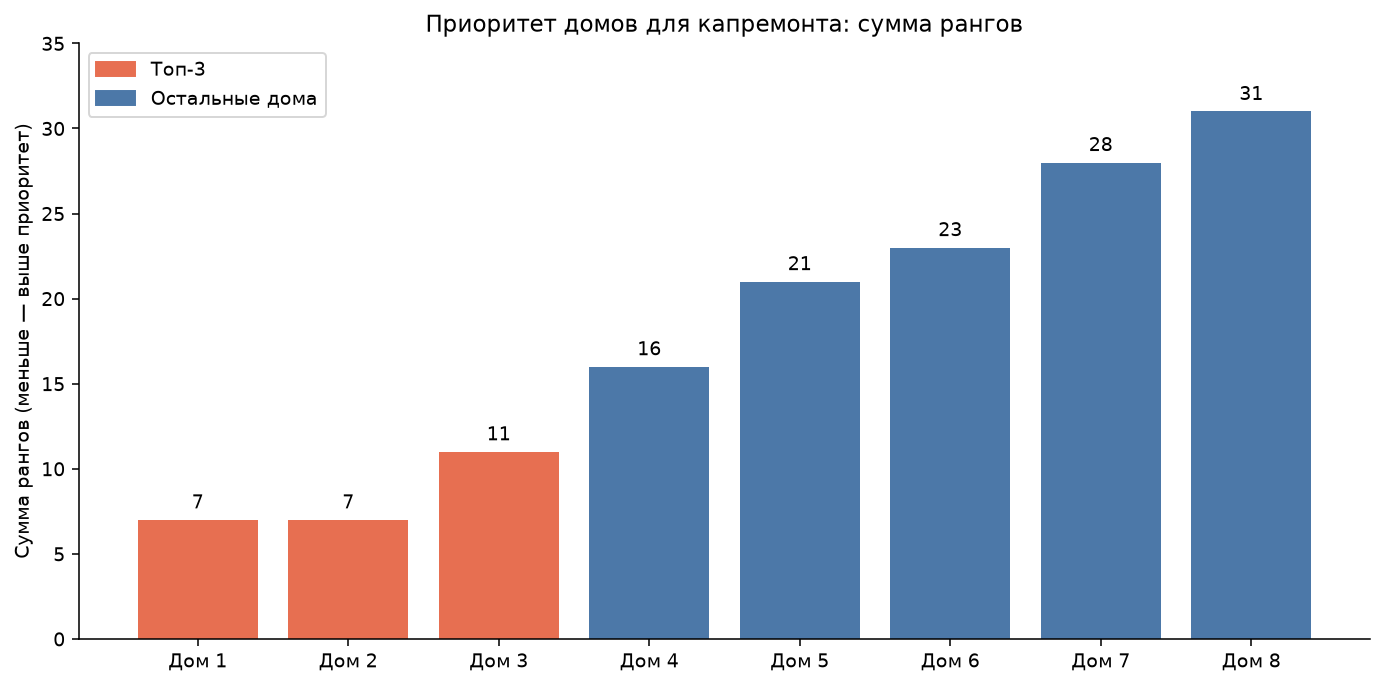

In [3]:
# Столбчатая диаграмма для задания 1.
priority_houses = set(top3["Дом"])
colors = ["#e76f51" if house in priority_houses else "#4c78a8"
          for house in house_rating["Дом"]]
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(house_rating["Дом"], house_rating["Сумма рангов"], color=colors)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            f"{bar.get_height():.0f}", ha="center", va="bottom")
ax.set_title("Приоритет домов для капремонта: сумма рангов")
ax.set_ylabel("Сумма рангов (меньше — выше приоритет)")
ax.set_ylim(0, max(result1["sums"]) + 4)
ax.legend(handles=[Patch(color="#e76f51", label="Топ-3"), Patch(color="#4c78a8", label="Остальные дома")])
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()



## Задание 2. Рейтинг управляющих компаний

Для совпадающих оценок в пределах строки эксперта используем средние ранги: например, два значения `2` у эксперта 2 занимают места 2 и 3 и получают ранг 2,5. Это сохраняет сумму рангов каждого эксперта равной $n(n+1)/2$ и позволяет применить поправку $T_i$ в знаменателе $W$.


In [4]:
# Задание 2: оценка управляющих компаний.
companies = ["Альфа", "Бета", "Гамма", "Старт", "Уют", "Прогресс"]
company_ranks = [
    [1, 3, 2, 5, 4, 6],
    [2, 2, 1, 4, 5, 6],
    [1, 4, 3, 3, 5, 6],
    [3, 1, 2, 5, 4, 5],
    [2, 3, 1, 6, 4, 5],
]
result2 = concordance(company_ranks)

print("ЗАДАНИЕ 2")
print("Связанные оценки преобразованы в средние ранги:")
display(pd.DataFrame(result2["ranks"],
                     index=[f"Эксперт {i}" for i in range(1, 6)],
                     columns=companies))
print(f"ΣT = {result2['tie_correction']}; S = {result2['S']:.1f}")
print(f"W с поправкой на связи = {result2['W']:.4f}")
print(f"χ²({result2['df']}) = {result2['chi_square']:.4f}; "
      f"p = {result2['p_value']:.6f} (приближение χ²)")
print("H0: согласованности между экспертами нет.")
if result2["p_value"] < alpha:
    print("При α = 0,05 отвергаем H0: согласованность статистически значима.")
else:
    print("При α = 0,05 нет оснований отвергнуть H0.")

company_rating = pd.DataFrame({"УК": companies, "Сумма средних рангов": result2["sums"]})
display(company_rating.sort_values("Сумма средних рангов", kind="stable"))
print("Вывод: мнения экспертов согласованы; рейтинг подходит для определения "
      "приоритетов дальнейшей проверки. Само согласие экспертов не подтверждает "
      "качество работы УК и не служит самостоятельным основанием для санкций.")



ЗАДАНИЕ 2
Связанные оценки преобразованы в средние ранги:
 Альфа  Бета  Гамма  Старт  Уют  Прогресс
   1.0   3.0    2.0    5.0  4.0       6.0
   2.5   2.5    1.0    4.0  5.0       6.0
   1.0   4.0    2.5    2.5  5.0       6.0
   3.0   1.0    2.0    5.5  4.0       5.5
   2.0   3.0    1.0    6.0  4.0       5.0
ΣT = 18; S = 332.5
W с поправкой на связи = 0.7733
χ²(5) = 19.3314; p = 0.001667 (приближение χ²)
H0: согласованности между экспертами нет.
При α = 0,05 отвергаем H0: согласованность статистически значима.
      УК  Сумма средних рангов
   Гамма                   8.5
   Альфа                   9.5
    Бета                  13.5
     Уют                  22.0
   Старт                  23.0
Прогресс                  28.5
Вывод: мнения экспертов согласованы; рейтинг подходит для определения приоритетов дальнейшей проверки. Само согласие экспертов не подтверждает качество работы УК и не служит самостоятельным основанием для санкций.


### Вывод по заданию 2

После перехода к средним рангам суммы по УК «Альфа», «Бета», «Гамма», «Старт», «Уют», «Прогресс» равны **9,5; 13,5; 8,5; 23; 22; 28,5**. Три группы совпадающих оценок по два объекта дают $\sum_i T_i=3(2^3-2)=18$. При $S=332{,}5$ получаем **$W=0{,}7733$** с поправкой на совпадения. Приближённая статистика $\chi^2(5)=19{,}3314$, $p=0{,}001667<0{,}05$: согласованность экспертных мнений статистически значима. Обобщённый порядок: **«Гамма», «Альфа», «Бета», «Уют», «Старт», «Прогресс»**. Рейтинг можно использовать для назначения дальнейшей проверки; для предписания или отзыва лицензии нужны самостоятельные доказательства нарушений. При пяти экспертах и шести объектах $\chi^2$-проверка является приближённой.
